<a href="https://colab.research.google.com/github/everestso/DeepLearningNotes/blob/main/c267f26_MNIST_Autoencoder_Latent_Space.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST Autoencoder: Exploring Latent Space

Change `LATENT_DIM` to compare compression, reconstruction, and decoding.
Run cells in order in Google Colab. PyTorch, torchvision, NumPy, and Matplotlib
are required; Colab normally includes them. MNIST downloads on the first run.
A GPU is optional (Colab: Runtime → Change runtime type → GPU).

This is a standard deterministic autoencoder. Labels are used only to select
and color examples, never to train the model. Random latent vectors are
experiments, not samples from a learned latent prior.


In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

LATENT_DIM = 4         # Try 2, 8, 16, 32, or 64; then rerun all cells.
EPOCHS = 10
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
TRAIN_LIMIT = None     # Or 10000 for a faster demonstration.
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cpu


## 1. Load images
`ToTensor()` maps pixels to [0, 1], matching the decoder's sigmoid output.
Each image has shape [1, 28, 28]. Training compares an image with itself,
so the target is the original image rather than its digit label.


In [2]:
train_data = datasets.MNIST('data', train=True, download=True,
                            transform=transforms.ToTensor())
test_data = datasets.MNIST('data', train=False, download=True,
                           transform=transforms.ToTensor())
if TRAIN_LIMIT is not None:
    if not 1 <= TRAIN_LIMIT <= len(train_data):
        raise ValueError('TRAIN_LIMIT must be between 1 and 60000.')
    indices = torch.randperm(len(train_data), generator=torch.Generator().manual_seed(SEED))
    train_data = Subset(train_data, indices[:TRAIN_LIMIT].tolist())

def make_train_loader():
    # Reset the shuffle seed for comparisons across latent dimensions.
    return DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 408kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.76MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.3MB/s]


## 2. Define the model
Architecture: 784 → 256 → 128 → latent dimensions → 128 → 256 → 784.
The latent layer is linear, so its coordinates can be positive or negative.
`encode` and `decode` are available separately; `forward` combines them.


In [3]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        if not isinstance(latent_dim, int) or latent_dim < 1:
            raise ValueError('latent_dim must be a positive integer.')
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),
        )

    def encode(self, images):
        return self.encoder(images)

    def decode(self, latent_vectors):
        # Accept [latent_dim] or [batch_size, latent_dim].
        if latent_vectors.ndim == 1:
            latent_vectors = latent_vectors.unsqueeze(0)
        if latent_vectors.ndim != 2 or latent_vectors.shape[1] != self.latent_dim:
            raise ValueError(f'Expected a vector of length {self.latent_dim} '
                             f'or a batch shaped [N, {self.latent_dim}].')
        return self.decoder(latent_vectors)

    def forward(self, images):
        return self.decode(self.encode(images))


## 3. Train and evaluate
The loss is mean squared error per pixel. Each batch produces one optimizer
update for all parameters. Test images are evaluated without updates.
Keep epochs, data, and architecture settings fixed when comparing dimensions.
Latent size also changes parameter count, so this is a practical comparison,
not an experiment that isolates dimensionality from model capacity.


latent= 4 epoch= 1/10 train MSE=0.05396 test MSE=0.03650
latent= 4 epoch= 2/10 train MSE=0.03436 test MSE=0.03280
latent= 4 epoch= 3/10 train MSE=0.03197 test MSE=0.03131
latent= 4 epoch= 4/10 train MSE=0.03077 test MSE=0.03041
latent= 4 epoch= 5/10 train MSE=0.02992 test MSE=0.02986
latent= 4 epoch= 6/10 train MSE=0.02927 test MSE=0.02920
latent= 4 epoch= 7/10 train MSE=0.02873 test MSE=0.02875
latent= 4 epoch= 8/10 train MSE=0.02834 test MSE=0.02840
latent= 4 epoch= 9/10 train MSE=0.02796 test MSE=0.02809
latent= 4 epoch=10/10 train MSE=0.02764 test MSE=0.02804


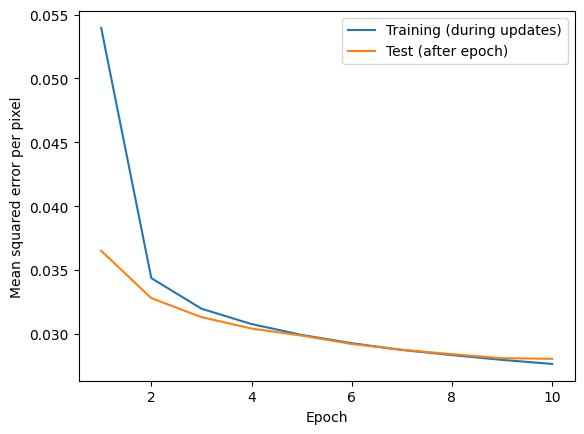

In [4]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    squared_error, pixels = 0.0, 0
    for images, _ in loader:
        images = images.to(device)
        squared_error += nn.functional.mse_loss(model(images), images, reduction='sum').item()
        pixels += images.numel()
    return squared_error / pixels

def train_autoencoder(latent_dim, epochs=EPOCHS):
    set_seed(SEED)
    model = Autoencoder(latent_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    history = {'train': [], 'test': []}
    train_loader = make_train_loader()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, count = 0.0, 0
        for images, _ in train_loader:
            images = images.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), images)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(images)
            count += len(images)
        history['train'].append(total_loss / count)
        history['test'].append(evaluate(model, test_loader))
        print(f'latent={latent_dim:2d} epoch={epoch:2d}/{epochs} '
              f'train MSE={history["train"][-1]:.5f} '
              f'test MSE={history["test"][-1]:.5f}')
    model.eval()
    return model, history

model, history = train_autoencoder(LATENT_DIM)
plt.plot(range(1, EPOCHS + 1), history['train'], label='Training (during updates)')
plt.plot(range(1, EPOCHS + 1), history['test'], label='Test (after epoch)')
plt.xlabel('Epoch'); plt.ylabel('Mean squared error per pixel')
plt.legend(); plt.show()


## 4. Compare original images with reconstructions
One held-out example of each digit is used in a fixed order.


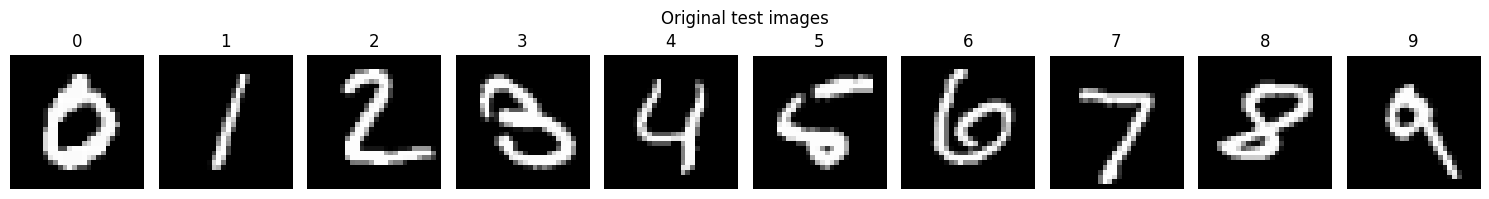

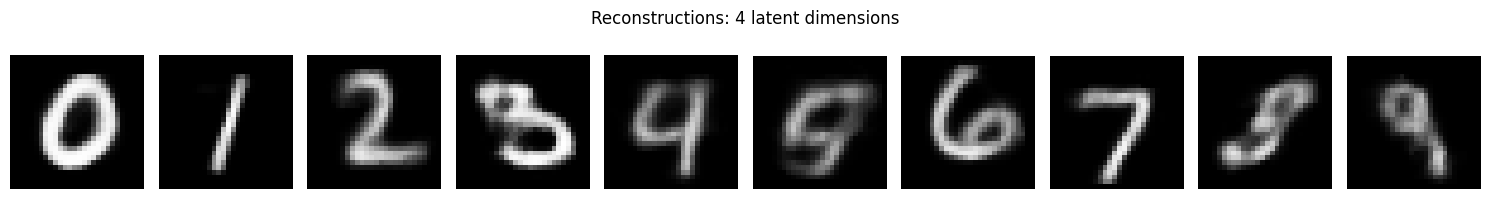

In [5]:
def show_images(images, title='', labels=None):
    images = images.detach().cpu()
    fig, axes = plt.subplots(1, len(images), figsize=(1.5 * len(images), 2), squeeze=False)
    for i, ax in enumerate(axes[0]):
        ax.imshow(images[i].squeeze(0), cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
        if labels is not None:
            ax.set_title(str(labels[i]))
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

example_indices = [int(torch.where(test_data.targets == d)[0][0]) for d in range(10)]
example_images = torch.stack([test_data[i][0] for i in example_indices])
with torch.inference_mode():
    latent_examples = model.encode(example_images.to(device))
    reconstructions = model.decode(latent_examples)
show_images(example_images, 'Original test images', list(range(10)))
show_images(reconstructions, f'Reconstructions: {model.latent_dim} latent dimensions')


## 5. Encode a 3, then run only the decoder
The saved vector represents this particular handwritten image, not its label.
You can edit its coordinates before decoding again.


Latent vector shape: (1, 4)
Latent vector: [[2.9788556 5.5121193 4.0961637 1.6071438]]


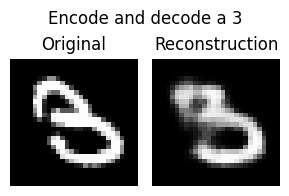

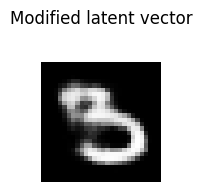

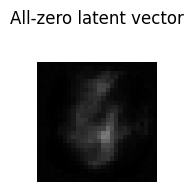

In [6]:
image_of_three = example_images[3:4].to(device)
with torch.inference_mode():
    z_three = model.encode(image_of_three)
    reconstructed_three = model.decode(z_three)
print('Latent vector shape:', tuple(z_three.shape))
print('Latent vector:', z_three.cpu().numpy())
show_images(torch.cat([image_of_three, reconstructed_three]),
            'Encode and decode a 3', ['Original', 'Reconstruction'])

@torch.inference_mode()
def decode_vectors(model, vectors):
    # Convenient entry point for Python lists, NumPy arrays, or tensors.
    parameter = next(model.parameters())
    vectors = torch.as_tensor(vectors, dtype=parameter.dtype, device=parameter.device)
    model.eval()
    return model.decode(vectors).cpu()

custom_vector = z_three.detach().cpu().clone()
custom_vector[0, 0] += 1.0   # Explore changes along the first latent coordinate.
show_images(decode_vectors(model, custom_vector), 'Modified latent vector')

# Any correctly sized list can also be decoded; recognizable output is not guaranteed.
zero_vector = [0.0] * model.latent_dim
show_images(decode_vectors(model, zero_vector), 'All-zero latent vector')


## 6. Interpolate between two examples
Try two different digits, or replace the endpoints with two images of the same
digit. Interpolation is not guaranteed to pass through meaningful images.


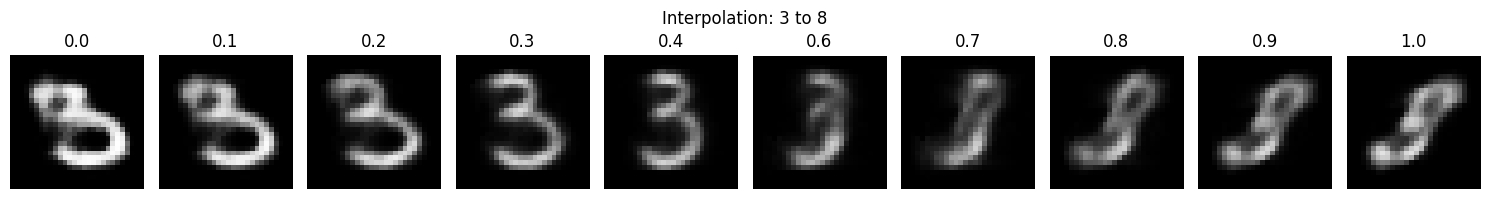

In [7]:
DIGIT_A, DIGIT_B = 3, 8
alphas = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
z_a = latent_examples[DIGIT_A:DIGIT_A + 1]
z_b = latent_examples[DIGIT_B:DIGIT_B + 1]
z_path = (1 - alphas) * z_a + alphas * z_b
show_images(decode_vectors(model, z_path), f'Interpolation: {DIGIT_A} to {DIGIT_B}',
            [f'{a:.1f}' for a in alphas[:, 0].cpu().tolist()])


## 7. Decode random vectors
Compare arbitrary standard-normal vectors with vectors scaled using encoded
training examples. Matching coordinate means and standard deviations does not
capture correlations or gaps in latent space. Neither approach is guaranteed
to produce recognizable digits, and neither is a learned generative prior.


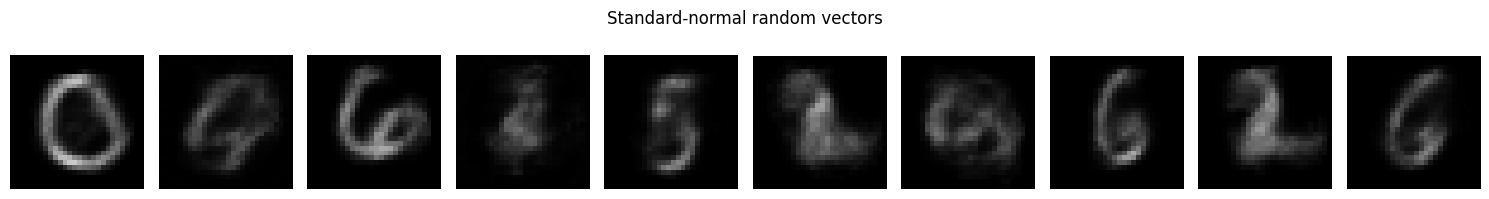

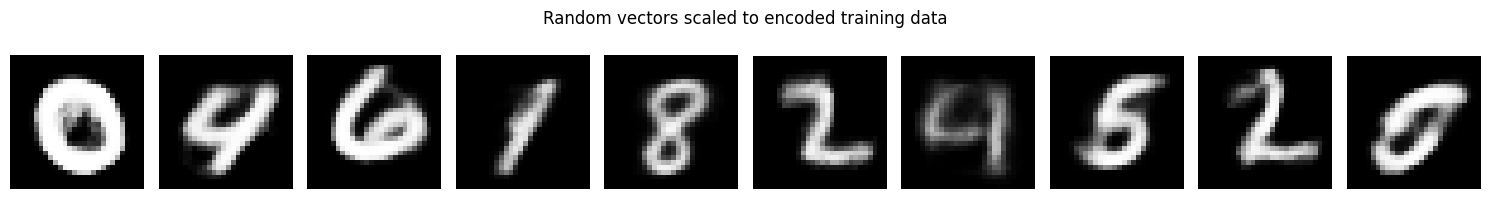

In [8]:
with torch.inference_mode():
    reference_images = torch.stack([train_data[i][0] for i in range(min(2000, len(train_data)))])
    reference_z = torch.cat([model.encode(batch.to(device))
                             for batch in reference_images.split(BATCH_SIZE)])
    latent_mean = reference_z.mean(0)
    latent_std = reference_z.std(0, unbiased=False).clamp_min(1e-6)
    rng = torch.Generator().manual_seed(SEED)
    noise = torch.randn(10, model.latent_dim, generator=rng).to(device)
    scaled_noise = latent_mean + latent_std * noise
show_images(decode_vectors(model, noise), 'Standard-normal random vectors')
show_images(decode_vectors(model, scaled_noise), 'Random vectors scaled to encoded training data')


## 8. Visualize a two-dimensional latent space
This cell runs only when `LATENT_DIM = 2`. The grid spans the central 96% of
encoded reference coordinates. Empty areas can decode poorly. Grid rows show
latent coordinate 2 increasing upwards; columns show coordinate 1 increasing
to the right. Digit labels color the plot only.


In [9]:
if model.latent_dim == 2:
    with torch.inference_mode():
        images = torch.stack([test_data[i][0] for i in range(2000)])
        codes = torch.cat([model.encode(b.to(device)).cpu() for b in images.split(BATCH_SIZE)])
    plt.figure(figsize=(7, 5))
    points = plt.scatter(codes[:, 0], codes[:, 1], c=test_data.targets[:2000],
                         cmap='tab10', s=8, alpha=0.7, vmin=-0.5, vmax=9.5)
    plt.colorbar(points, ticks=range(10), label='Digit label')
    plt.xlabel('Latent coordinate 1'); plt.ylabel('Latent coordinate 2')
    plt.title('Encoded test images'); plt.show()

    bounds = torch.quantile(reference_z.cpu(), torch.tensor([0.02, 0.98]), dim=0)
    n = 12
    x_values = torch.linspace(bounds[0, 0], bounds[1, 0], n)
    y_values = torch.linspace(bounds[1, 1], bounds[0, 1], n)
    yy, xx = torch.meshgrid(y_values, x_values, indexing='ij')
    grid_vectors = torch.stack([xx.reshape(-1), yy.reshape(-1)], dim=1)
    decoded = decode_vectors(model, grid_vectors).reshape(n, n, 28, 28)
    mosaic = decoded.permute(0, 2, 1, 3).reshape(n * 28, n * 28)
    plt.figure(figsize=(8, 8))
    plt.imshow(mosaic, cmap='gray', vmin=0, vmax=1)
    plt.xticks([]); plt.yticks([])
    plt.xlabel('Latent coordinate 1 increases →')
    plt.ylabel('Latent coordinate 2 increases ↑')
    plt.title('Decode a grid of latent vectors'); plt.show()
else:
    print('Set LATENT_DIM = 2 and rerun all cells to view the latent-space map.')


Set LATENT_DIM = 2 and rerun all cells to view the latent-space map.


## Optional: compare several latent sizes in one run
Set `RUN_COMPARISON = True`. This trains fresh models and can take several
times longer. It uses the same held-out images for each row. The original
`model` remains available for the earlier decoder experiments.
Test scores are descriptive comparisons; repeatedly choosing settings on the
test set turns it into a validation set, so reserve another holdout for final claims.


In [ ]:
RUN_COMPARISON = False
if RUN_COMPARISON:
    dimensions = [2, 8, 32]
    fig, axes = plt.subplots(len(dimensions) + 1, 10, figsize=(14, 6))
    for j in range(10):
        axes[0, j].imshow(example_images[j, 0], cmap='gray', vmin=0, vmax=1)
        axes[0, j].set_title(str(j)); axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    axes[0, 0].set_ylabel('Original')
    for row, dim in enumerate(dimensions, start=1):
        comparison_model, comparison_history = train_autoencoder(dim)
        with torch.inference_mode():
            outputs = comparison_model(example_images.to(device)).cpu()
        for j in range(10):
            axes[row, j].imshow(outputs[j, 0], cmap='gray', vmin=0, vmax=1)
            axes[row, j].set_xticks([]); axes[row, j].set_yticks([])
        axes[row, 0].set_ylabel(f'Latent {dim}')
        print(f'Final test MSE for {dim} dimensions: {comparison_history["test"][-1]:.5f}')
        del comparison_model
    plt.tight_layout(); plt.show()


## Discussion
1. Which details disappear first as the bottleneck shrinks?
2. Are low reconstruction error and recognizable random samples the same goal?
3. Does interpolation between two 3s behave differently from interpolation between a 3 and an 8?
4. Why does adjusting random-vector scale help without guaranteeing good samples?

Reference: [torchvision MNIST documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).


# Example
# Dim=16

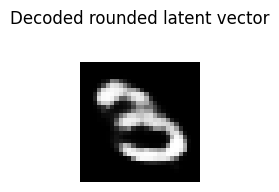

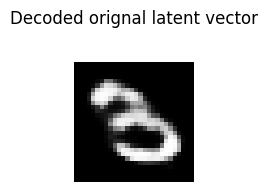

In [13]:
# Custom Vector from
# [[10.874599   -0.14850727 -5.6294713   6.0503836  -4.21102    -3.9483047
#   0.02378362  4.942381    1.4969816  -8.506685   -2.1771731  -2.1014893
#   3.5446782  10.381266   -0.87631905 12.293058  ]]
original_vector = [[10.874599, -0.14850727, -5.6294713,   6.0503836,  -4.21102,    -3.9483047,
   0.02378362,  4.942381,    1.4969816,  -8.506685,   -2.1771731,  -2.1014893,
   3.5446782,  10.381266,   -0.87631905, 12.293058  ]]

# Rounded latent vector: 16 whole-number values
custom_vector = [
    11, 0, -6, 6, -4, -4, 0, 5,
    1, -9, -2, -2, 4, 10, -1, 12
]

images = decode_vectors(model, custom_vector)
show_images(images, "Decoded rounded latent vector")
images = decode_vectors(model, original_vector)
show_images(images, "Decoded orignal latent vector")


# Example
# Dim=4

z_one=tensor([[-1.4929, -9.1627, -1.4706,  8.0121]]), z_seven=tensor([[ -3.3475, -12.2791,   3.1029,  -0.1853]])


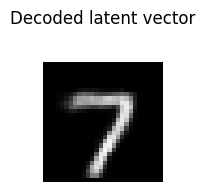

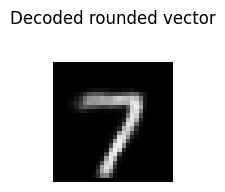

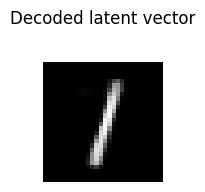

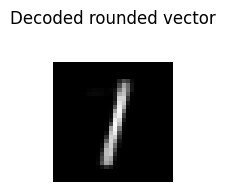

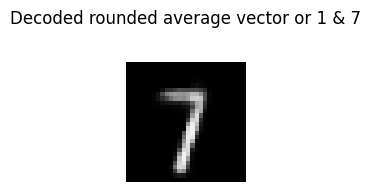

In [24]:
dim = 4
image_of_one = example_images[1:2].to(device)
image_of_seven = example_images[7:8].to(device)

with torch.inference_mode():
    z_one = model.encode(image_of_one)
    z_seven = model.encode(image_of_seven)

print (f"{z_one=}, {z_seven=}")

images = decode_vectors(model, z_seven)
show_images(images, "Decoded latent vector")

# z_seven=tensor([[ -3.3475, -12.2791,   3.1029,  -0.1853]])
z_7a = [ -3.0, -12.0,   3.0,  -0.0]

images = decode_vectors(model, z_7a)
show_images(images, "Decoded rounded vector")

images = decode_vectors(model, z_one)
show_images(images, "Decoded latent vector")

# z_one=tensor([[-1.4929, -9.1627, -1.4706,  8.0121]])
z_1a = [-1, -9.0,   -1.0,  8.0]

images = decode_vectors(model, z_1a)
show_images(images, "Decoded rounded vector")

z_mid = [(z_1 + z_7)/2 for z_1, z_7 in zip(z_1a, z_7a)]
images = decode_vectors(model, z_mid)
show_images(images, "Decoded rounded average vector or 1 & 7")